# Winding and scaled susceptibility: clean-system measurements

27 points: $L=32,64,128$ (that is $L^2$ sites), nine temperatures $T/t=1/\beta$ with $t=1$.
All have $U/t=0.152$, $V=0$, $n_{\max}=5$ and $N/L^2=1.8310546875$.

The main plots use the **final production window only**, with **one-standard-error bars from whole-rank jackknifing**. These are conditional on independent, equilibrated rank streams. Equilibration and cutoff convergence are not certified by a small error bar. The original pooled-three-window notebook is a different estimate.

This notebook uses ordinary analysis cells and plots, with no custom functions. All inputs needed to rerun it are in this folder; large restart checkpoints are unnecessary. See [README](README.md) and the [main guide, §11.6](../../COMPLETE_BKT_GUIDE.md#116-equal-time-susceptibility-and-reliable-error-bars).

In [1]:
from pathlib import Path
import csv
import html
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

folder = Path.cwd()
if not (folder / 'data/baseline_summary.csv').exists():
    folder = next(p / 'results/response_measurements' for p in [folder, *folder.parents]
                  if (p / 'results/response_measurements/data/baseline_summary.csv').exists())
figures = folder / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
colors = {32: '#3265a8', 64: '#ce7732', 128: '#278263'}
with (folder / 'data/baseline_rank_observables.csv').open(newline='') as stream:
    rank_records = list(csv.DictReader(stream))
baseline = np.genfromtxt(folder / 'data/baseline_summary.csv', names=True, delimiter=',',
                         dtype=None, encoding='utf-8')
print(f'{len(baseline)} points; {len(rank_records)} rank records; all baseline values from prod03.')

27 points; 520 rank records; all baseline values from prod03.


## Observables and error bars

$W^2=W_x^2+W_y^2$: sum of squared winding numbers, **without division by two**. For a square isotropic system the dimensionless stiffness is $\beta\rho_s=\langle W^2\rangle/2$; $4/\pi$ is the thermodynamic BKT reference for the sum, not an exact finite-size crossing criterion.

The paper's equal-time susceptibility becomes
$\chi_s=\sum_{\mathbf r}G(\mathbf r)=N/L^2+\sum_{\mathbf r\ne0}G(\mathbf r)$.
It is the zero-momentum occupation, not a density/compressibility response. The on-site term uses exact canonical density to avoid the known special-estimator defect. Do not add a beta factor, another volume division or radial weights. The plotted leading BKT scaling is $\chi_s/L^{7/4}$; logarithmic and finite-size corrections remain.
[Carleo et al.](https://arxiv.org/html/1305.3032v3) define this susceptibility and scaling.

Sum spatial bins or winding directions **inside each rank first**. For each observable use its own measurement count as weight. Delete a whole rank, recompute the weighted mean, then use
$\mathrm{SE}^2=(R-1)\sum_r(\theta_{(-r)}-\overline\theta_{(-r)})^2/R$.
This retains the relevant spatial/directional covariance and treats each complete chain history as one unit. Different production windows of a continued chain are not independent replicas.

In [2]:
# Recompute every reported mean and error directly from the portable rank records.
checked = []
for point in baseline:
    L, beta = int(point['L']), float(point['beta'])
    rows = [r for r in rank_records if int(r['L']) == L and float(r['beta']) == beta]
    R = len(rows)
    row_result = {'L': L, 'beta': beta}
    for observable, weight_key in [('chi_scaled', 'g_count'), ('W2', 'w_count')]:
        if observable == 'chi_scaled':
            values = np.array([float(r['G_offsite_sum']) + int(r['N']) / L**2 for r in rows]) / L**1.75
        else:
            values = np.array([float(r['Wx2']) + float(r['Wy2']) for r in rows])
        counts = np.array([int(r[weight_key]) for r in rows])
        total = np.dot(values, counts)
        mean = total / counts.sum()
        omitted = (total - values * counts) / (counts.sum() - counts)
        se = np.sqrt((R - 1) / R * np.sum((omitted - omitted.mean())**2))
        assert np.isclose(mean, point[observable], rtol=1e-10, atol=1e-12)
        assert np.isclose(se, point[observable + '_se'], rtol=1e-10, atol=1e-12)
        row_result[observable], row_result[observable + '_se'] = mean, se
    checked.append(row_result)
print('Verified all 54 means and all 54 standard errors against the saved summary.')

Verified all 54 means and all 54 standard errors against the saved summary.


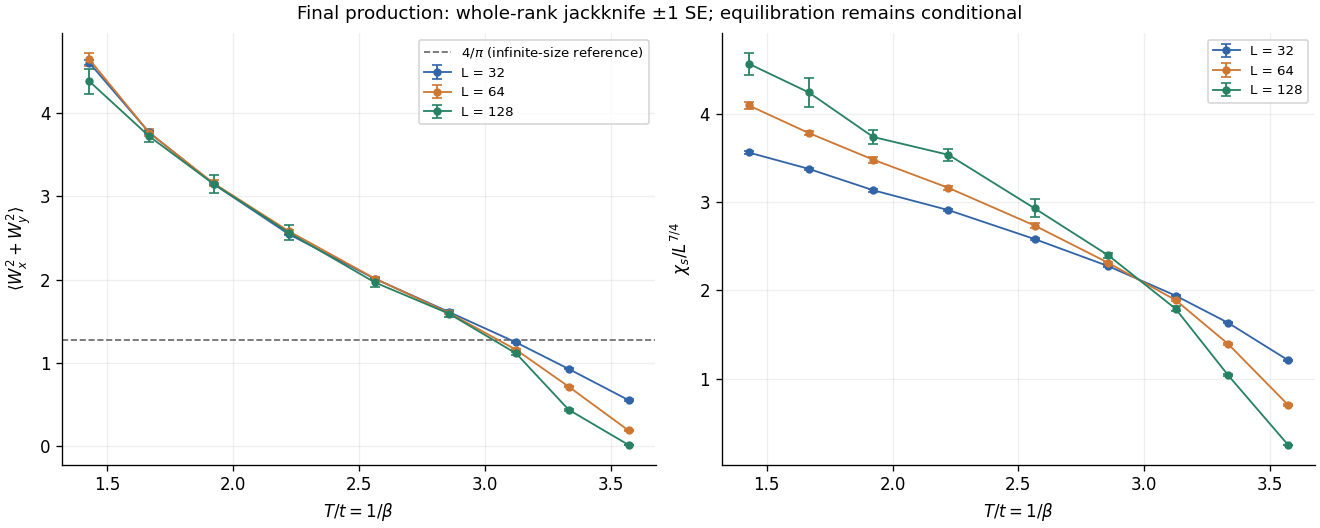

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for L in [32, 64, 128]:
    points = np.sort(baseline[baseline['L'] == L], order='T')
    for ax, name in zip(axes, ['W2', 'chi_scaled']):
        ax.errorbar(points['T'], points[name], yerr=points[name + '_se'],
                    fmt='o-', ms=4, capsize=3, lw=1.1, color=colors[L], label=f'L = {L}')
axes[0].axhline(4 / np.pi, color='0.4', ls='--', lw=1, label=r'$4/\pi$ (infinite-size reference)')
axes[0].set_ylabel(r'$\langle W_x^2+W_y^2\rangle$')
axes[1].set_ylabel(r'$\chi_s/L^{7/4}$')
for ax in axes:
    ax.set_xlabel(r'$T/t=1/\beta$')
    ax.legend(fontsize=8)
fig.suptitle('Final production: whole-rank jackknife ±1 SE; equilibration remains conditional', fontsize=11)
fig.savefig(figures / 'baseline_observables.png', dpi=180)
plt.show()

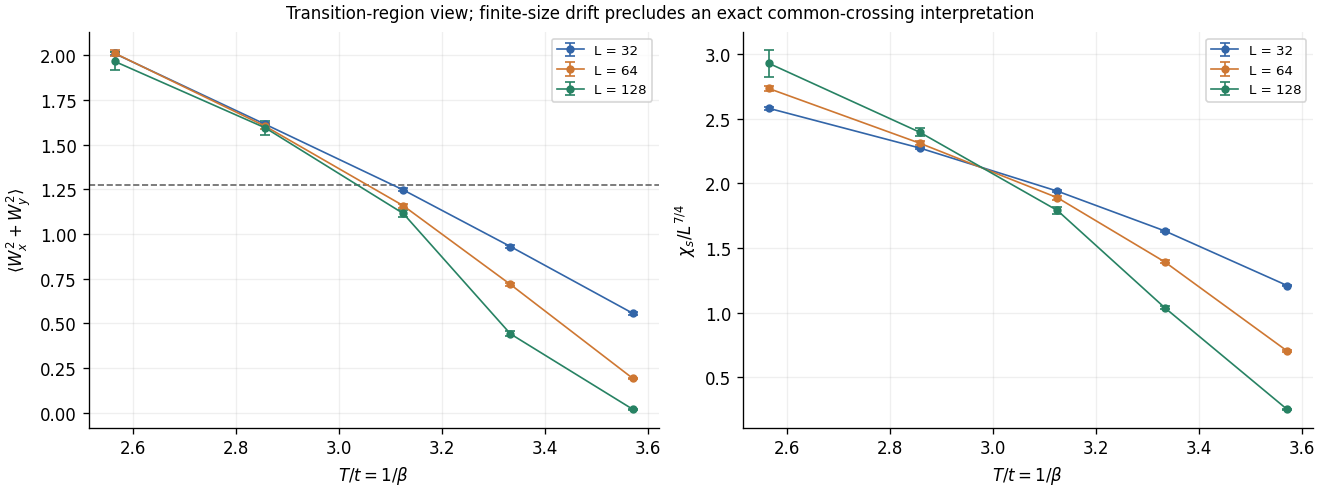

In [4]:
# Close-up of the transition region; the same data and errors, with no fit.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
for L in [32, 64, 128]:
    points = np.sort(baseline[(baseline['L'] == L) & (baseline['beta'] <= 0.39)], order='T')
    for ax, name in zip(axes, ['W2', 'chi_scaled']):
        ax.errorbar(points['T'], points[name], yerr=points[name + '_se'], fmt='o-',
                    ms=4, capsize=3, lw=1, color=colors[L], label=f'L = {L}')
axes[0].axhline(4 / np.pi, color='0.4', ls='--', lw=1)
axes[0].set_ylabel(r'$\langle W_x^2+W_y^2\rangle$')
axes[1].set_ylabel(r'$\chi_s/L^{7/4}$')
for ax in axes:
    ax.set_xlabel(r'$T/t=1/\beta$')
    ax.legend(fontsize=8)
fig.suptitle('Transition-region view; finite-size drift precludes an exact common-crossing interpretation', fontsize=10)
fig.savefig(figures / 'transition_region.png', dpi=180)
plt.show()

In [5]:
# Full measurement table. R is the number of rank clusters, not the number of intervals.
headers = ['L', 'sites', 'beta', 'T/t', 'ranks', 'min G intervals/rank', 'W² ± SE', 'chi/L^1.75 ± SE', 'relative SE (W², chi)']
body = []
for p in baseline:
    fields = [str(p['L']), str(int(p['L'])**2), f"{p['beta']:.2f}", f"{p['T']:.4f}", str(p['ranks']),
              str(p['g_count_min']), f"{p['W2']:.5f} ± {p['W2_se']:.5f}",
              f"{p['chi_scaled']:.5f} ± {p['chi_scaled_se']:.5f}",
              f"{100*p['W2_relative_se']:.2f}%, {100*p['chi_relative_se']:.2f}%"]
    body.append('<tr>' + ''.join('<td>' + html.escape(v) + '</td>' for v in fields) + '</tr>')
display(HTML('<table><thead><tr>' + ''.join('<th>' + v + '</th>' for v in headers)
             + '</tr></thead><tbody>' + ''.join(body) + '</tbody></table>'))
print('All 27 chi SEs are below 5%; 26/27 W² SEs are below 5%.')
print('At L=128, beta=.28, W² is near zero; the absolute SE is below .02.')
print('These precision statements do not establish equilibrium or a temporal blocking plateau.')

All 27 chi SEs are below 5%; 26/27 W² SEs are below 5%.
At L=128, beta=.28, W² is near zero; the absolute SE is below .02.
These precision statements do not establish equilibrium or a temporal blocking plateau.


L,sites,beta,T/t,ranks,min G intervals/rank,W² ± SE,chi/L^1.75 ± SE,"relative SE (W², chi)"
32,1024,0.28,3.5714,24,19,0.55583 ± 0.00762,1.20948 ± 0.00470,"1.37%, 0.39%"
32,1024,0.30,3.3333,24,19,0.93005 ± 0.00691,1.63321 ± 0.00563,"0.74%, 0.34%"
32,1024,0.32,3.1250,24,19,1.24706 ± 0.00822,1.94072 ± 0.00774,"0.66%, 0.40%"
32,1024,0.35,2.8571,24,17,1.61409 ± 0.00552,2.27548 ± 0.00956,"0.34%, 0.42%"
32,1024,0.39,2.5641,24,14,2.01065 ± 0.00926,2.58285 ± 0.01088,"0.46%, 0.42%"
32,1024,0.45,2.2222,24,11,2.54507 ± 0.00763,2.91041 ± 0.00949,"0.30%, 0.33%"
32,1024,0.52,1.9231,24,7,3.14685 ± 0.01653,3.13602 ± 0.01600,"0.53%, 0.51%"
32,1024,0.60,1.6667,24,6,3.76613 ± 0.01859,3.37847 ± 0.01281,"0.49%, 0.38%"
32,1024,0.70,1.4286,24,5,4.60327 ± 0.03172,3.56379 ± 0.01791,"0.69%, 0.50%"
64,4096,0.28,3.5714,24,17,0.19128 ± 0.00453,0.70232 ± 0.00667,"2.37%, 0.95%"


## Supplemental simulations: keep the lineages separate

Four 600-second, eight-rank warm continuations were collected at $(L,\beta)=(128,.28),(128,.30),(128,.45),(64,.70)$.
They start from copied final checkpoint states/RNG streams, so they are **paired continuations of existing ranks**, not eight fresh independent starts. They are diagnostics and are not substituted into the 27-point baseline.

Settings: `Nmeasure=1`, `Nmeasure2=100`, **`Nresponse_measure=10`**, `Nresponse_max_blocks=1000000`, `C_worm=2`.
The scalar recorder sums off-site hits during each interval, includes zero-hit intervals, and pairs chi with winding and density over the same ten eligible closed update calls. Partial intervals survive checkpoint continuation but do not enter the completed-interval mean. Physical controls are unchanged.

The next cells independently recompute the pilot rank errors and temporal reblocking curves from the saved NPZ histories. At each blocking size, adjacent intervals are combined **within a rank**. The blocked SE assumes those blocks have become approximately independent; a plateau and adequate block count must be checked before using it. Rank-jackknife SE and blocked SE are shown separately.

In [6]:
pilot_paths = sorted((folder / 'sampling').glob('*/history.npz'))
pilots, pilot_curves, series_by_point = [], [], {}
for path in pilot_paths:
    with np.load(path, allow_pickle=False) as archive:
        L, beta, interval = int(archive['L']), float(archive['beta']), int(archive['interval'])
        rank_ids = sorted(int(k.split('_')[0][4:]) for k in archive.files if k.endswith('_chi_s'))
        series = []
        for rank in rank_ids:
            prefix = f'rank{rank}_'
            counts = archive[prefix + 'sweep_count']
            ends = archive[prefix + 'end_sweep']
            assert np.all(counts == interval) and np.all(np.diff(ends) == interval)
            assert np.allclose(archive[prefix + 'density'], int(archive['N']) / L**2)
            series.append(np.column_stack((archive[prefix + 'w2'], archive[prefix + 'chi_s'] / L**1.75)))
    rank_counts = np.array([len(values) for values in series])
    rank_sums = np.array([values.sum(axis=0) for values in series])
    mean = rank_sums.sum(axis=0) / rank_counts.sum()
    omitted = (rank_sums.sum(axis=0) - rank_sums) / (rank_counts.sum() - rank_counts)[:, None]
    se = np.sqrt((len(series)-1) / len(series) * np.sum((omitted - omitted.mean(axis=0))**2, axis=0))
    pilots.append({'point': path.parent.name, 'L': L, 'beta': beta, 'mean': mean, 'se': se,
                   'min_intervals': rank_counts.min(), 'total_intervals': rank_counts.sum()})
    series_by_point[path.parent.name] = series
    block_size = 1
    while min(len(values) // block_size for values in series) >= 2:
        block_means, kept, rank_variances, numbers = [], [], [], []
        for values in series:
            number = len(values) // block_size
            blocks = values[:number * block_size].reshape(number, block_size, 2).mean(axis=1)
            block_means.append(blocks.mean(axis=0))
            rank_variances.append(blocks.var(axis=0, ddof=1) / number)
            kept.append(number * block_size)
            numbers.append(number)
        weights = np.array(kept) / np.sum(kept)
        block_se = np.sqrt(np.sum(weights[:, None]**2 * np.array(rank_variances), axis=0))
        pilot_curves.append({'point': path.parent.name, 'block': block_size,
                             'se': block_se, 'min_blocks': min(numbers), 'total_blocks': sum(numbers)})
        block_size *= 2
    print(f'{path.parent.name}: {rank_counts.sum():,} intervals, minimum {rank_counts.min():,}/rank; '
          f'W²={mean[0]:.5f} ± {se[0]:.5f}, scaled chi={mean[1]:.5f} ± {se[1]:.5f}')

l128t028: 109,779 intervals, minimum 12,559/rank; W²=0.01006 ± 0.00210, scaled chi=0.25201 ± 0.00497
l128t030: 23,542 intervals, minimum 2,626/rank; W²=0.38913 ± 0.01917, scaled chi=0.96404 ± 0.02756
l128t045: 4,392 intervals, minimum 488/rank; W²=2.54966 ± 0.13051, scaled chi=3.39307 ± 0.09175
l64t070: 9,299 intervals, minimum 1,083/rank; W²=4.66855 ± 0.10204, scaled chi=3.98947 ± 0.06981


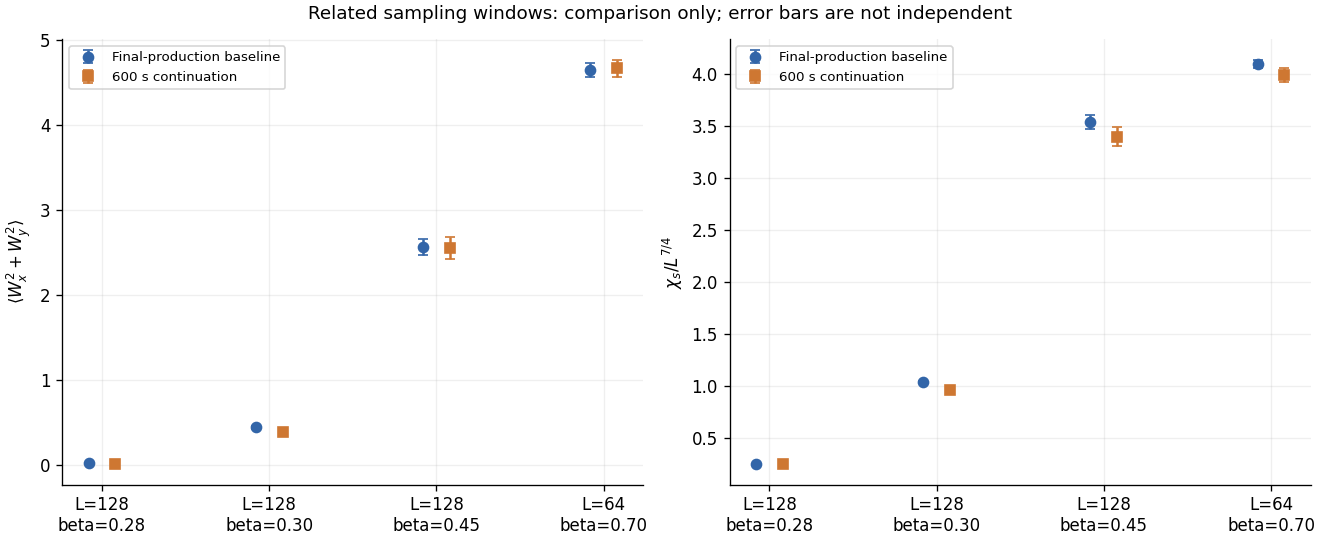

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
x = np.arange(len(pilots))
for col, (ax, name) in enumerate(zip(axes, ['W2', 'chi_scaled'])):
    old = [baseline[(baseline['L'] == p['L']) & (baseline['beta'] == p['beta'])][0] for p in pilots]
    ax.errorbar(x - .08, [p[name] for p in old], yerr=[p[name + '_se'] for p in old],
                fmt='o', capsize=3, color='#3265a8', label='Final-production baseline')
    ax.errorbar(x + .08, [p['mean'][col] for p in pilots], yerr=[p['se'][col] for p in pilots],
                fmt='s', capsize=3, color='#ce7732', label='600 s continuation')
    ax.set_xticks(x, [f"L={p['L']}\nbeta={p['beta']:.2f}" for p in pilots])
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'$\langle W_x^2+W_y^2\rangle$')
axes[1].set_ylabel(r'$\chi_s/L^{7/4}$')
fig.suptitle('Related sampling windows: comparison only; error bars are not independent', fontsize=11)
fig.savefig(figures / 'baseline_and_pilots.png', dpi=180)
plt.show()

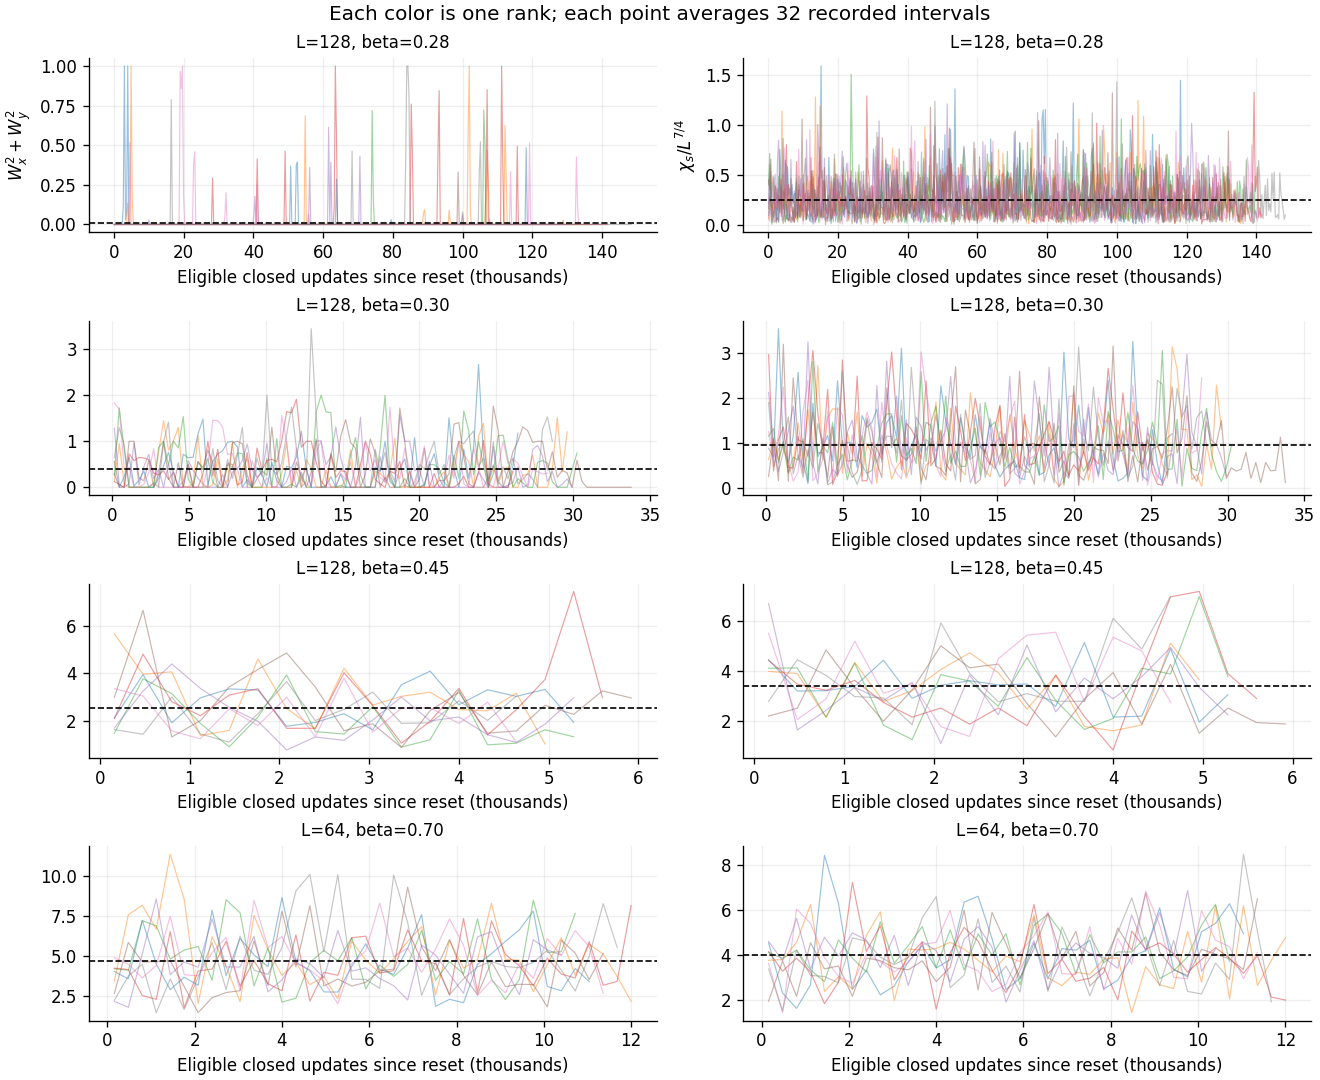

In [8]:
# Short disjoint averages expose chronology; they are not independent error estimates.
fig, axes = plt.subplots(len(pilots), 2, figsize=(11, 9), constrained_layout=True)
for row, p in enumerate(pilots):
    for values in series_by_point[p['point']]:
        width = 32
        number = len(values) // width
        trace = values[:number * width].reshape(number, width, 2).mean(axis=1)
        updates = (np.arange(number) + .5) * width * 10 / 1000
        for col in [0, 1]:
            axes[row, col].plot(updates, trace[:, col], alpha=.45, lw=.7)
    for col in [0, 1]:
        axes[row, col].axhline(p['mean'][col], color='black', lw=1, ls='--')
        axes[row, col].set_title(f"L={p['L']}, beta={p['beta']:.2f}", fontsize=10)
        axes[row, col].set_xlabel('Eligible closed updates since reset (thousands)')
axes[0, 0].set_ylabel(r'$W_x^2+W_y^2$')
axes[0, 1].set_ylabel(r'$\chi_s/L^{7/4}$')
fig.suptitle('Each color is one rank; each point averages 32 recorded intervals', fontsize=12)
fig.savefig(figures / 'pilot_traces.png', dpi=160)
plt.show()

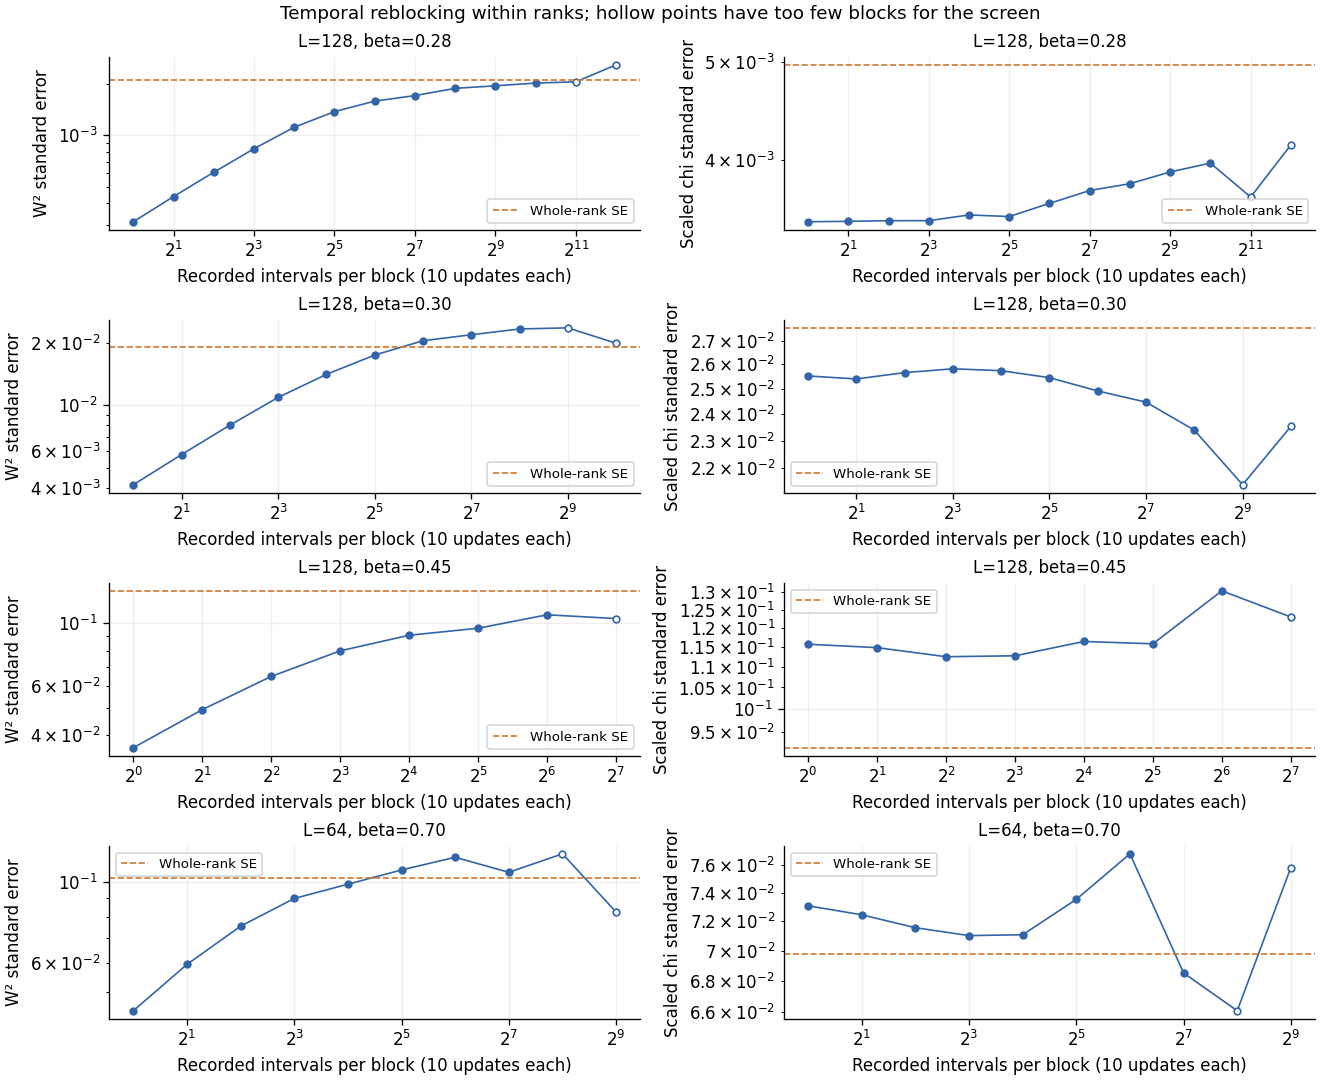

In [9]:
fig, axes = plt.subplots(len(pilots), 2, figsize=(11, 9), constrained_layout=True)
for row, p in enumerate(pilots):
    curve = [v for v in pilot_curves if v['point'] == p['point']]
    for col in [0, 1]:
        ax = axes[row, col]
        ax.plot([v['block'] for v in curve], [v['se'][col] for v in curve], color='#3265a8', lw=1)
        for v in curve:
            adequate_count = v['total_blocks'] >= 50 and v['min_blocks'] >= 4
            ax.plot(v['block'], v['se'][col], 'o', ms=4, color='#3265a8',
                    markerfacecolor='#3265a8' if adequate_count else 'white')
        ax.axhline(p['se'][col], color='#ce7732', ls='--', lw=1, label='Whole-rank SE')
        ax.set_xscale('log', base=2)
        ax.set_yscale('log')
        ax.set_title(f"L={p['L']}, beta={p['beta']:.2f}", fontsize=10)
        ax.set_xlabel('Recorded intervals per block (10 updates each)')
        ax.set_ylabel('W² standard error' if col == 0 else 'Scaled chi standard error')
        ax.legend(fontsize=8)
fig.suptitle('Temporal reblocking within ranks; hollow points have too few blocks for the screen', fontsize=11)
fig.savefig(figures / 'pilot_blocking.png', dpi=160)
plt.show()

## Reading the diagnostics and planning the next production

The saved `analysis/summary.csv` also contains paired late-minus-early changes, approximate autocorrelation times and a conservative plateau screen. The screen requires three consecutive blocking sizes to give SEs within 25%, enough blocks, and block sizes longer than the estimated correlation time. These numerical checks help select what to inspect; **they cannot certify equilibration**, especially with only eight rank lineages.

A 5% relative-SE planning target is used for both observables, with an absolute $W^2$ SE target of 0.02 near zero. Both the rank SE and a usable blocked SE must meet the target. If no plateau is demonstrated, the temporal error is unresolved even when the rank error is small. The half-window checks retain rank pairing; failure to detect drift is not evidence that drift is absent.

In [10]:
with (folder / 'analysis/summary.csv').open(newline='') as stream:
    diagnostics = list(csv.DictReader(stream))
headers = ['L', 'beta', 'min intervals/rank', 'precision target', 'blocking screen', 'status / flags']
body = []
for row in diagnostics:
    p = next(p for p in pilots if p['L'] == int(row['L']) and p['beta'] == float(row['beta']))
    assert np.allclose(p['mean'], [float(row['W2sum']), float(row['scaled_chi'])])
    assert np.allclose(p['se'], [float(row['W2sum_se']), float(row['scaled_chi_se'])])
    fields = [row['L'], row['beta'], row['min_intervals_per_rank'], row['precision_target_met'],
              row['statistical_diagnostics_met'], row['flags'] or 'Numerical screen only; independent equilibration review required']
    body.append('<tr>' + ''.join('<td>' + html.escape(str(v)) + '</td>' for v in fields) + '</tr>')
display(HTML('<table><thead><tr>' + ''.join('<th>' + h + '</th>' for h in headers)
             + '</tr></thead><tbody>' + ''.join(body) + '</tbody></table>'))
print('All supplemental rank means and errors match the saved diagnostic summary.')

All supplemental rank means and errors match the saved diagnostic summary.


L,beta,min intervals/rank,precision target,blocking screen,status / flags
128,0.28,12559,True,True,Numerical screen only; independent equilibration review required
128,0.3,2626,False,True,precision_target_not_met
128,0.45,488,False,False,blocking_plateau_not_demonstrated;precision_target_not_met
64,0.7,1083,True,True,Numerical screen only; independent equilibration review required


For new sampling:

1. Keep the physical controls, canonical particle number, cutoff, rank identity and seed lineage recorded. Check contrasting initial states; a warm continuation does not supply that check.
2. Start with `Nmeasure=1`, `Nresponse_measure=10`, `Nmeasure2=100` (or 1000 if spatial-array cost dominates), and preserve ordered scalar histories. Smaller intervals improve diagnostic resolution, not independent information.
3. Choose burn-in from energy, winding, density and coherence stability across starts. The configured threshold alone is not evidence of equilibrium.
4. Reblock separately within each rank. Aim for 50–100 **long, decorrelated blocks per rank** and compare successive production windows. A numerical screen based on fewer blocks is preliminary.
5. If a plateau begins at $k$ response intervals, collecting $B$ long blocks needs at least $B\,k\,N_{\rm response}$ eligible updates per rank after burn-in. Measure the cost at the largest lattice; wall-clock seconds do not specify sample count.
6. Once stationary blocking is established, use $\text{length}_{new}/\text{length}_{old}\approx(\mathrm{SE}_{old}/\mathrm{SE}_{target})^2$ to plan precision. Extend the slower observable, then repeat the checks. Without a plateau this extrapolation is only a rough budget.

**Remaining limits:** the L128 beta=.30 pilot needs more winding statistics; L128 beta=.45 needs longer blocking histories as well. The baseline errors remain conditional on equilibrium for all 27 points. Cutoff convergence of nmax=5 and finite-size/logarithmic corrections require separate physical checks before quoting a precise transition temperature.

The [folder README](README.md) gives commands, actual counts, validation and restart instructions. The complete means and SEs are in [baseline_summary.csv](data/baseline_summary.csv), with all 520 rank inputs retained.